# Auditoria Financeira Determinística, Elasticidade de Preço e Risco de Margem no E-commerce Brasileiro

**Contexto de Negócio:** Operações de varejo digital e *cross-docking/dropshipping* B2B no Brasil (`Supplier_B2B` → `Marketplace_BR`) sofrem erosão silenciosa de margem por quatro vetores principais:
1. **Assimetria de Regime Tributário e Comissionamento:** Contas CPF Padrão vs. CPF Alto Volume (sobretaxa por item) vs. CNPJ Simples Nacional (alíquota fiscal sobre faturamento bruto).
2. **Saltos de Faixa de Preço:** Mudanças abruptas na taxa fixa por unidade (ex.: R$ 4,50 até R$ 79,99 → R$ 16,00 entre R$ 80,00 e R$ 99,99).
3. **Retenção de Frete por Peso/Cubagem:** Divergências entre peso cadastrado e cubagem logística geram descontos líquidos negativos no repasse.
4. **Descasamento de CPA em Tráfego Pago:** Campanhas com custo por aquisição acima da margem de contribuição unitária geram crescimento sem lucro.

Este notebook integra:
- **Motor Determinístico (`Decimal`)** com precisão de centavos (`ROUND_HALF_UP`) e **Matcher NLP de Títulos em Português**;
- **Camada SQL Analítica** (DDL PostgreSQL validado em SQLite com *Window Functions*);
- **Clusterização Não Supervisionada (`KMeans`)** para Matriz BCG/Margem de SKUs;
- **Classificação Supervisionada *Leak-Free*** comparando `LogisticRegression`, `RandomForestClassifier` e `GradientBoostingClassifier`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.audit_engine import calculate_expected_marketplace_fees, match_title_to_catalog
from src.run_sql_validation import run_sql_validation

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 3)

sku_df = pd.read_csv(PROJECT_ROOT / 'data' / 'sku_catalog.csv')
orders_df = pd.read_csv(PROJECT_ROOT / 'data' / 'orders_reconciliation.csv')
metrics_json = json.loads((PROJECT_ROOT / 'reports' / 'ml_metrics.json').read_text(encoding='utf-8'))
clusters_df = pd.read_csv(PROJECT_ROOT / 'reports' / 'sku_clusters.csv')

print(f'Catálogo de SKUs: {sku_df.shape[0]} SKUs | {sku_df.shape[1]} colunas')
print('Origem dos SKUs:', sku_df['data_origin'].value_counts().to_dict())
print(f'Base de Pedidos: {orders_df.shape[0]} pedidos | {orders_df.shape[1]} colunas')
print('Origem dos Pedidos:', orders_df['data_origin'].value_counts().to_dict())

Catálogo de SKUs: 64 SKUs | 21 colunas
Origem dos SKUs: {'SYNTHETIC_AUGMENTED': 40, 'OBSERVED_SANITIZED': 24}
Base de Pedidos: 500 pedidos | 42 colunas
Origem dos Pedidos: {'SYNTHETIC_AUGMENTED': 484, 'OBSERVED_SANITIZED': 16}


## 1. Reconciliação Determinística (`Decimal`) dos Registros Piloto Observados e Matcher NLP

Os 16 registros reais sanitizados (`OBSERVED_SANITIZED`, `OBS-M01` a `OBS-M16`) servem como referência verificável de auditoria contábil:
- **Ajuste de Fluxo de Caixa (`OBS-M02`):** Recarga automática de anúncios retida no repasse é reconciliada sem distorcer a contribuição econômica real.
- **Guarda de Reembolso (`OBS-M05`):** Pedidos reembolsados sem comprovação de estorno são isolados como `SUSPEITA` (`partial_contribution_brl = NaN`).
- **Retenção de Frete Negativo:** Descontos de cubagem/envio reverso são sinalizados pela regra `RULE_02_FREIGHT_AND_RETENTION_AUDIT`.

In [2]:
obs_df = orders_df[orders_df['data_origin'] == 'OBSERVED_SANITIZED'].copy()
cols_obs = [
    'order_id', 'sku', 'item_price_brl', 'coupon_brl', 'net_shipping_brl',
    'reported_fees_brl', 'cash_flow_adjustment_brl', 'observed_payout_brl',
    'supplier_cost_brl', 'partial_contribution_brl', 'audit_classification', 'is_healthy_margin'
]
display(obs_df[cols_obs])
print(f"Contribuição parcial acumulada (15 pedidos calculáveis): R$ {obs_df['partial_contribution_brl'].sum():.2f}")

# Demonstração do Matcher NLP por Tokens em Português
catalog_records = [
    {'sku': row['sku'], 'title': row['product_title'], 'keywords': row['category'].split()}
    for _, row in sku_df.iterrows()
]
exemplos_ads = [
    'Dinossauro T-Rex Brinquedo Rugido com Som e Luz [1]',
    'Forma Silicone Pão de Queijo 7 Cavidades Air Fryer',
    'Mini Mop Limpeza Portátil Pia Vidros'
]
for ad_title in exemplos_ads:
    matched_sku, score, layer = match_title_to_catalog(ad_title, catalog_records)
    print(f"Anúncio: '{ad_title}' -> SKU={matched_sku} | Score={score:.3f} | Camada={layer}")

,order_id,sku,item_price_brl,coupon_brl,net_shipping_brl,reported_fees_brl,cash_flow_adjustment_brl,observed_payout_brl,supplier_cost_brl,partial_contribution_brl,audit_classification,is_healthy_margin
0,OBS-M01,DIN24116,69.90,0.00,0.00,18.48,0.00,51.42,28.99,22.43,OK,1
1,OBS-M02,DIN24116,69.90,3.50,-2.42,14.98,10.49,38.51,28.99,20.01,ERRO_COMPROVADO,0
2,OBS-M03,DIN24116,69.90,3.50,-1.21,14.98,0.00,50.21,28.99,21.22,ERRO_COMPROVADO,0
3,OBS-M04,TRC0304,22.90,0.00,-2.44,8.58,0.00,11.88,8.99,2.89,ERRO_COMPROVADO,0
4,OBS-M05,TRC0304,22.90,0.00,0.00,NaN,0.00,0.00,8.99,NaN,SUSPEITA,0
5,OBS-M06,DIN24116,59.41,2.98,0.00,13.40,0.00,43.03,28.99,14.04,OK,1
6,OBS-M07,TRC0304,22.90,0.00,-1.21,8.58,0.00,13.11,8.99,4.12,ERRO_COMPROVADO,0
7,OBS-M08,CO0961295,54.99,0.00,0.00,15.50,0.00,39.49,32.99,6.50,OK,0
8,OBS-M09,15-64150,69.90,0.00,0.00,17.98,0.00,51.92,44.99,6.93,OK,0
9,OBS-M10,TRC0304,22.90,0.00,0.00,8.58,0.00,14.32,8.99,5.33,OK,1


Contribuição parcial acumulada (15 pedidos calculáveis): R$ 129.83
Anúncio: 'Dinossauro T-Rex Brinquedo Rugido com Som e Luz [1]' -> SKU=DIN24116 | Score=0.507 | Camada=LAYER_3_NLP_TOKENS
Anúncio: 'Forma Silicone Pão de Queijo 7 Cavidades Air Fryer' -> SKU=TRC0304 | Score=0.627 | Camada=LAYER_3_NLP_TOKENS
Anúncio: 'Mini Mop Limpeza Portátil Pia Vidros' -> SKU=MINI-MOP-01 | Score=0.775 | Camada=LAYER_3_NLP_TOKENS


## 2. Análise Exploratória de Dados (EDA) & Testes Estatísticos

Avaliamos a distribuição da margem líquida entre os pedidos liquidados (`audit_classification != 'SUSPEITA'`), verificando hipóteses de negócio:
1. **H1 (Peso/Cubagem vs. Retenção de Frete):** Pedidos com frete líquido negativo possuem peso significativamente maior do que pedidos sem retenção?
2. **H2 (Markup vs. Margem Líquida):** Qual a correlação não paramétrica de Spearman entre `markup_ratio` e `net_margin_pct`?

Distribuição de Classificação da Auditoria:


,pedidos
audit_classification,
OK,299
ERRO_COMPROVADO,187
SUSPEITA,14


Estatísticas Descritivas das Variáveis Financeiras (pedidos calculáveis):


,count,mean,std,min,50%,max
item_price_brl,486.0,74.609,53.064,13.190,59.765,373.860
supplier_cost_brl,486.0,33.432,23.340,6.200,25.995,138.510
weight_kg,486.0,0.271,0.097,0.103,0.286,0.719
expected_fees_brl,486.0,23.489,15.927,7.140,17.775,112.350
net_shipping_brl,486.0,-0.389,0.909,-4.770,0.000,0.000
ads_spend_brl,486.0,2.427,3.531,0.000,0.000,15.520
net_profit_brl,486.0,11.257,15.833,-16.500,7.500,99.220
net_margin_pct,486.0,11.996,14.732,-74.630,14.390,43.400


H1 Mann-Whitney (Peso com frete < 0 vs >= 0): mediana_neg=0.329kg vs mediana_ok=0.262kg | U=22840.0, p=7.5960e-08
H2 Spearman (Markup Ratio vs Margem Líquida %): rho=0.7412, p=7.8749e-86


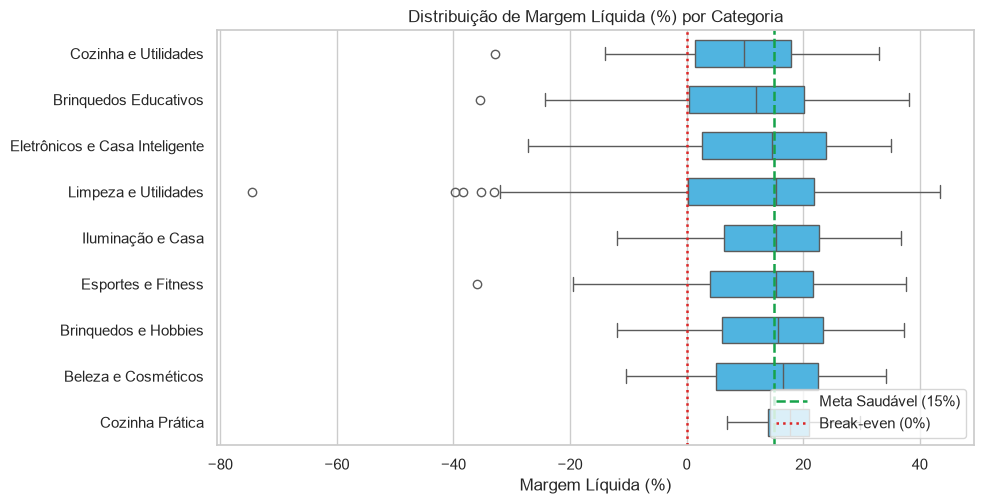

In [3]:
valid_orders = orders_df[orders_df['audit_classification'] != 'SUSPEITA'].copy()
print('Distribuição de Classificação da Auditoria:')
display(orders_df['audit_classification'].value_counts().to_frame('pedidos'))

print('Estatísticas Descritivas das Variáveis Financeiras (pedidos calculáveis):')
num_summary_cols = ['item_price_brl', 'supplier_cost_brl', 'weight_kg', 'expected_fees_brl', 'net_shipping_brl', 'ads_spend_brl', 'net_profit_brl', 'net_margin_pct']
display(valid_orders[num_summary_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# Teste Mann-Whitney U: peso em pedidos com frete negativo vs frete zerado
w_neg = valid_orders.loc[valid_orders['net_shipping_brl'] < 0, 'weight_kg']
w_ok = valid_orders.loc[valid_orders['net_shipping_brl'] >= 0, 'weight_kg']
u_stat, p_mw = stats.mannwhitneyu(w_neg, w_ok, alternative='greater')
rho, p_sp = stats.spearmanr(valid_orders['markup_ratio'], valid_orders['net_margin_pct'])
print(f'H1 Mann-Whitney (Peso com frete < 0 vs >= 0): mediana_neg={w_neg.median():.3f}kg vs mediana_ok={w_ok.median():.3f}kg | U={u_stat:.1f}, p={p_mw:.4e}')
print(f'H2 Spearman (Markup Ratio vs Margem Líquida %): rho={rho:.4f}, p={p_sp:.4e}')

fig, ax = plt.subplots(figsize=(10, 5.2))
cat_order = valid_orders.groupby('category')['net_margin_pct'].median().sort_values().index.tolist()
sns.boxplot(data=valid_orders, y='category', x='net_margin_pct', order=cat_order, color='#38bdf8', width=0.58, ax=ax)
ax.axvline(15.0, color='#16a34a', linestyle='--', linewidth=1.8, label='Meta Saudável (15%)')
ax.axvline(0.0, color='#dc2626', linestyle=':', linewidth=1.8, label='Break-even (0%)')
ax.set_title('Distribuição de Margem Líquida (%) por Categoria')
ax.set_xlabel('Margem Líquida (%)')
ax.set_ylabel('')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

## 3. Validação do Modelo Relacional SQL (`dim_sku_catalog`, `fact_orders_reconciliation`, `mart_margin_risk`)

Validamos o schema PostgreSQL (`sql/schema_postgresql.sql`) e todas as 7 queries analíticas (`sql/analytical_queries.sql`) executando-as via SQLite em memória.

In [4]:
sql_summary = run_sql_validation()
print(f"Queries validadas: {sql_summary['queries_passed']}/{sql_summary['queries_executed']} | Mart rows: {sql_summary['mart_margin_risk_rows']}")

for qid in ['q1_margin_by_category', 'q2_freight_weight_impact', 'q3_cpf_vs_cnpj_regime', 'q5_sku_cpa_roi_and_elasticity_ranking']:
    print(f'\n--- {qid} ---')
    display(pd.DataFrame(sql_summary['results'][qid]['rows']))

Queries validadas: 7/7 | Mart rows: 207

--- q1_margin_by_category ---


,category,total_orders,total_gmv_brl,total_net_profit_brl,avg_net_margin_pct,healthy_order_rate_pct,divergence_rate_pct
0,Cozinha Prática,16,1033.97,191.93,17.65,62.50,6.25
1,Brinquedos e Hobbies,42,3789.48,641.72,15.50,28.57,33.33
2,Iluminação e Casa,74,6871.09,1107.40,14.23,37.84,28.38
3,Beleza e Cosméticos,76,5271.72,762.60,13.17,40.79,21.05
4,Esportes e Fitness,66,4711.07,788.91,12.47,37.88,30.30
5,Eletrônicos e Casa Inteligente,38,4243.43,666.46,12.03,36.84,31.58
6,Cozinha e Utilidades,59,2472.21,296.88,9.38,27.12,30.51
7,Brinquedos Educativos,55,3375.33,350.92,8.94,38.18,32.73
8,Limpeza e Utilidades,60,4491.78,664.11,8.63,43.33,28.33



--- q2_freight_weight_impact ---


,weight_bracket,total_orders,avg_weight_kg,negative_freight_orders,freight_loss_incidence_pct,avg_freight_deduction_brl,avg_net_margin_pct
0,1_LEVE_ATE_200G,149,0.161,11,7.38,-0.11,17.25
1,2_MEDIO_201G_A_350G,222,0.278,39,17.57,-0.38,9.56
2,3_PESADO_ACIMA_350G,115,0.400,33,28.70,-0.78,9.89



--- q3_cpf_vs_cnpj_regime ---


,account_regime,total_orders,avg_ticket_brl,avg_contractual_fee_pct,avg_effective_fee_pct,avg_tax_pct,avg_net_margin_pct,healthy_rate_pct
0,CPF_PADRAO,161,64.31,32.30,32.34,0.0,14.04,40.99
1,CNPJ_SIMPLES_4PCT,130,80.24,30.84,31.19,4.0,12.39,37.69
2,CNPJ_SIMPLES_6PCT,90,82.39,30.79,31.10,6.0,10.76,38.89
3,CPF_ALTO_VOLUME,105,76.76,38.43,39.48,0.0,9.43,31.43



--- q5_sku_cpa_roi_and_elasticity_ranking ---


,sku,category,competition_level,orders_count,avg_realized_margin_pct,cpa_target_brl,cpa_roi_ratio,price_elasticity_coef,cpa_roi_rank
0,SYN-BRI-024,Brinquedos e Hobbies,LOW,2,25.75,3.65,5.466,-1.022,1
1,SYN-LIM-034,Limpeza e Utilidades,LOW,3,25.25,6.01,4.304,-1.067,2
2,SYN-ILU-004,Iluminação e Casa,MODERATE,8,26.91,11.78,4.108,-1.436,3
3,SYN-LIM-026,Limpeza e Utilidades,LOW,6,18.10,4.80,3.929,-1.016,4
4,SYN-ELE-039,Eletrônicos e Casa Inteligente,MODERATE,7,26.02,9.53,3.910,-1.421,5
5,SYN-ELE-007,Eletrônicos e Casa Inteligente,LOW,3,17.13,5.23,3.646,-1.065,6
6,SYN-COZ-009,Cozinha e Utilidades,MODERATE,9,20.86,4.59,3.586,-1.385,7
7,SYN-BEL-013,Beleza e Cosméticos,MODERATE,5,22.40,8.17,3.536,-1.456,8
8,SYN-ESP-003,Esportes e Fitness,MODERATE,5,20.29,5.57,3.528,-1.454,9
9,SYN-ESP-019,Esportes e Fitness,HIGH,13,24.61,9.45,3.223,-2.169,10


## 4. Clusterização Não Supervisionada de Portfólio (Matriz BCG / Margem — `KMeans`)

Segmentamos os 64 SKUs usando `StandardScaler + KMeans (k=4)` sobre margem líquida efetiva, demanda mensal (log), proxy de giro de estoque e nível de competição.

KMeans k=4 | Silhouette Score = 0.2538 | Grid = {'k=3': 0.2305, 'k=4': 0.2528, 'k=5': 0.2633}


,cluster_id,cluster_label,sku_count,mean_margin_pct,mean_monthly_search,mean_turnover_proxy,mean_competition_score,mean_cpa_roi
0,0,Alto Volume & Competição Elevada,21,15.45,43520.5,30.40,3.76,2.32
1,1,Zona Crítica (Margem Pressionada / Negativa),9,-9.17,31228.4,19.87,2.56,0.53
2,2,Nicho Equilibrado (Baixa Competição),29,15.49,20794.0,18.78,2.31,2.68
3,3,Estrelas de Alto Giro (Top Margem & ROI),5,21.06,28460.2,83.22,2.40,3.34


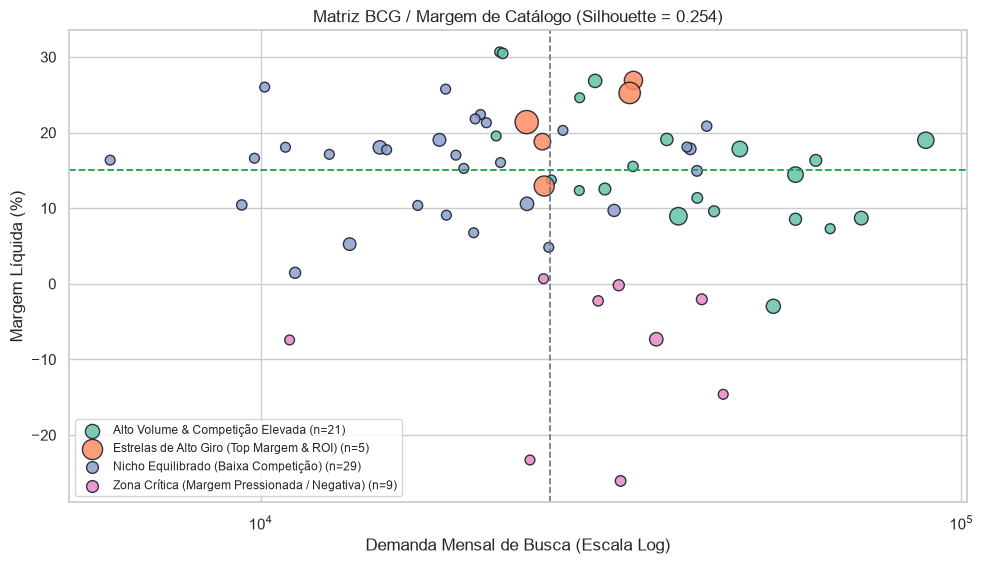

In [5]:
clus_meta = metrics_json['unsupervised_clustering']
print(f"KMeans k={clus_meta['chosen_k']} | Silhouette Score = {clus_meta['silhouette_score']:.4f} | Grid = {clus_meta['silhouette_grid']}")
display(pd.DataFrame(clus_meta['clusters']))

fig, ax = plt.subplots(figsize=(10, 5.8))
palette = sns.color_palette('Set2', n_colors=clus_meta['chosen_k'])
for idx, label in enumerate(sorted(clusters_df['cluster_label'].unique())):
    sub = clusters_df[clusters_df['cluster_label'] == label]
    ax.scatter(
        sub['monthly_search_volume'],
        sub['effective_margin_pct'],
        s=np.clip(sub['turnover_proxy'] * 2.5, 50, 420),
        alpha=0.85,
        edgecolors='#0f172a',
        color=palette[idx],
        label=f'{label} (n={len(sub)})'
    )
ax.axhline(15.0, color='#16a34a', linestyle='--', linewidth=1.3)
ax.axvline(clusters_df['monthly_search_volume'].median(), color='#64748b', linestyle='--', linewidth=1.2)
ax.set_xscale('log')
ax.set_title(f"Matriz BCG / Margem de Catálogo (Silhouette = {clus_meta['silhouette_score']:.3f})")
ax.set_xlabel('Demanda Mensal de Busca (Escala Log)')
ax.set_ylabel('Margem Líquida (%)')
ax.legend(loc='lower left', fontsize=8.5)
fig.tight_layout()
plt.show()

## 5. Modelagem Supervisionada *Leak-Free*: Predição de Margem Saudável (`is_healthy_margin`)

Treinamos 3 algoritmos via `Pipeline + ColumnTransformer` usando **apenas atributos ex-ante** (preço, custo fornecedor, peso, cubagem, markup, regime fiscal, canal de tráfego e concorrência — sem qualquer coluna pós-liquidação como taxa cobrada, frete retido ou repasse).

Modelo Campeão: RandomForestClassifier | Taxa Positiva Global: 36.60%


,Modelo,CV_Accuracy,CV_F1,CV_ROC_AUC,Holdout_Accuracy,Holdout_F1,Holdout_ROC_AUC
1,RandomForestClassifier,0.755,0.645,0.830,0.720,0.588,0.816
2,GradientBoostingClassifier,0.752,0.660,0.841,0.768,0.701,0.814
0,LogisticRegression,0.749,0.637,0.831,0.720,0.607,0.813


,feature,importance_mean,importance_std
0,traffic_channel,6.420e-02,0.024
1,markup_ratio,4.320e-02,0.027
2,gross_spread_pct,1.960e-02,0.019
3,expected_fee_ratio,1.560e-02,0.007
4,price_vs_market_avg_ratio,1.210e-02,0.015
5,account_regime,3.800e-03,0.004
6,coupon_pct,1.300e-03,0.002
7,volumetric_cm3,1.300e-03,0.008
8,expected_tax_pct,7.000e-04,0.002
9,item_price_brl,-6.000e-04,0.007


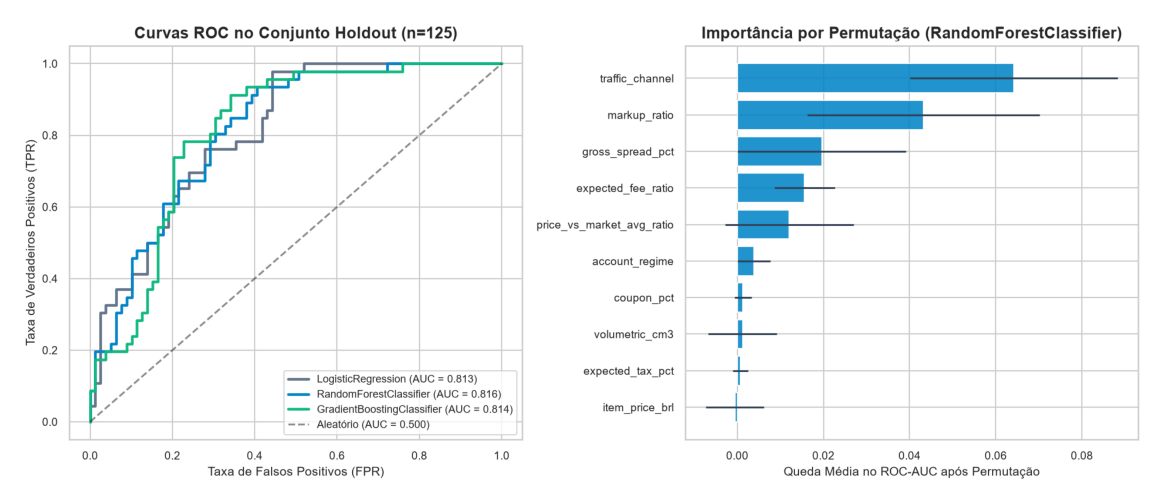

In [6]:
sup_meta = metrics_json['supervised_classification']
rows_comp = []
for mname, mvals in sup_meta['models'].items():
    rows_comp.append({
        'Modelo': mname,
        'CV_Accuracy': mvals['cv_5fold']['accuracy_mean'],
        'CV_F1': mvals['cv_5fold']['f1_mean'],
        'CV_ROC_AUC': mvals['cv_5fold']['roc_auc_mean'],
        'Holdout_Accuracy': mvals['holdout']['accuracy'],
        'Holdout_F1': mvals['holdout']['f1_score'],
        'Holdout_ROC_AUC': mvals['holdout']['roc_auc'],
    })
comp_df = pd.DataFrame(rows_comp).sort_values('Holdout_ROC_AUC', ascending=False)
print(f"Modelo Campeão: {sup_meta['best_model_name']} | Taxa Positiva Global: {sup_meta['positive_class_rate']:.2%}")
display(comp_df)

imp_df = pd.DataFrame(sup_meta['top_features_permutation'])
display(imp_df)

img = plt.imread(PROJECT_ROOT / 'reports' / 'figures' / 'classifier_roc_and_importance.png')
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.imshow(img)
ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Conclusões Executivas e Recomendações de Operação

1. **Precificação Guiada por Markup e Break-even:** As variáveis `gross_spread_pct`, `markup_ratio` e `traffic_channel` lideram o poder preditivo do risco de margem — SKUs com markup inferior a ~1.85x dificilmente sustentam margem líquida >= 15% quando expostos a tráfego pago e cupons.
2. **Gestão de Peso e Cubagem:** Produtos acima de 350g concentram maior incidência de retenção líquida de frete, exigindo margem de segurança adicional no preço ou revisão cadastral de embalagem junto ao fornecedor.
3. **Estratégia Fiscal (CPF Alto Volume vs. CNPJ Simples Nacional):** A sobretaxa por volume no CPF pune severamente itens de ticket baixo/médio, tornando o regime CNPJ Simples 4% estruturalmente mais competitivo conforme escala operacional.
4. **Auditoria Híbrida (Determinística + ML):** O motor `Decimal` garante tolerância zero para erros de repasse (contestáveis com trilha SHA-256), enquanto o modelo de Machine Learning atua preventivamente no momento do cadastro/campanha antes da erosão acontecer.